In [3]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_regression, mutual_info_classif

In [4]:
df=pd.read_csv("/content/railway.csv")

In [5]:
#data check data type:
def convert_variables(datatype,var,format="mixed"):
  if datatype=="Datetime":
    df[var]=pd.to_datetime(df[var],errors="coerce",format="mixed")
  elif datatype=="numerical":
    df[var]=pd.to_numeric(df[var],errors="coerce")
  elif datatype=="categorical":
    df[var]=str(df[var])
  else:
    print("invalid datatype")
  return df[var], df.dtypes

In [6]:
#data understanding
def classify_variables(data):
  numerical_col=df.select_dtypes(include=np.number).columns
  datetime_col=df.select_dtypes(include="datetime").columns
  categorical_col=df.select_dtypes(exclude=[np.number,"datetime"]).columns
  return numerical_col,categorical_col, datetime_col

def overview():
  print(f" the total number of object variables = {(df.select_dtypes(include='object').dtypes).count()} \n and the total number of numerical variables = {(df.select_dtypes(include='number').dtypes).count()}")
  print(f"shape: {df.shape} \n the duplicates:{df.duplicate.sum()}")
  print(f"the missing values:{df.isnull.sum()} \n ")
  print(f"the statistical summary for categorical {df.decribe(include="object")} \n")
  print(f"the statistical summary for numerical {df.decribe()} \n")






In [7]:
# data cleanning
def handling_missing_values(variable,values):
    if df[variable].dtypes == 'object':
        df[variable].fillna(values,inplace=True)
        return df[variable].unique()
    elif values == 'mean':
         df[variable].fillna(df[variable].mean(),inplace=True)
         print(f'this is the mean of the {variable} : {df[variable].mean()} \n')
         return df[df[variable]]
    elif values == 'median':
        df[variable].fillna(df[variable].median(),inplace=True)
        print(f'this is the mean of the {variable} : {df[variable].median()} \n')
    elif values == 'mode':
        df[variable].fillna(df[variable].mode(),inplace=True)
        print(f'this is the mode of the {variable} : {df[variable].mode()} \n')
        return df[variable]

In [8]:
def correct_inconsistency(col_name,value_Error,correct_value):
    df[col_name] = np.where(
    df[col_name] == value_Error,
    correct_value,
    df[col_name]
                            )
    return df[col_name].unique()

In [9]:
# =========================================================
# PRINT HELPERS
# =========================================================

def print_section(title):
    print("\n" + "="*60)
    print(title)
    print("="*60)

def print_list(title, items):
    print(f"\n{title}")
    if items:
        for i in items:
            print(f"  - {i}")
    else:
        print("  - None")

def print_distribution(y, title):
    print_section(title)
    dist = y.value_counts(normalize=True) * 100
    for k, v in dist.items():
        print(f"  Class {k}: {v:.2f}%")

In [10]:
# -------------------------------------------------------
# 6. ENCODE CATEGORICAL VARIABLES
# -------------------------------------------------------

def encode_categorical(df, method="frequency", target_variable=None):
    """
    Encode categorical variables.

    Small category variables (<10) → One-Hot Encoding.
    Large category variables → Frequency or Target encoding.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataset.

    method : str
        Encoding method for large categories:
        "frequency" or "target".

    target_variable : str
        Required when method="target".

    Returns
    -------
    pandas.DataFrame
        New DataFrame with encoded categorical variables.
    """

    new_df = df.copy()

    cat_cols = new_df.select_dtypes(include="object").columns

    # exclude target colomn:

    if target_variable is not None:
        cat_cols = [col for col in cat_cols if col != target_variable]


    if len(cat_cols) == 0:
        return new_df

    for col in cat_cols:

        if new_df[col].nunique() < 10:

            dummies = pd.get_dummies(new_df[col], prefix=col)

            new_df = pd.concat([new_df.drop(col, axis=1), dummies], axis=1)

        else:

            if method == "frequency": #--> Used when categories are many

                freq = new_df[col].value_counts() / len(new_df)

                new_df[col] = new_df[col].map(freq)

            elif method == "target":  #--> Used when target variable exists

                if target_variable is None or target_variable not in new_df.columns:
                    raise ValueError("target_variable must be provided")

                target_mean = new_df.groupby(col)[target_variable].mean()

                new_df[col] = new_df[col].map(target_mean)

    return new_df


In [11]:
# =========================================================
# 1. FILTER SELECTION
# =========================================================

from scipy.stats import chi2_contingency

def filter_selection(df, target_variable, alpha=0.05, del_flag=True):
    """
    Filter selection following the PDF logic:
    - Categorical predictors vs categorical target -> Chi-square
    - Numeric / ordinal predictors vs target -> Mutual Information
    """

    print("\n" + "=" * 70)
    print("FILTER SELECTION START")
    print("=" * 70)

    new_df = df.copy()

    if target_variable not in new_df.columns:
        raise ValueError("Target variable not found")

    X = new_df.drop(columns=[target_variable]).copy()
    y = new_df[target_variable].copy()
    removed_features = []

    print("Original dataframe shape:", new_df.shape)
    print("\nTarget variable:", target_variable)
    print("X shape:", X.shape)
    print("y shape:", y.shape)
    print("y dtype:", y.dtype)

    # -------------------------------------------------
    # Encode target only for MI
    # -------------------------------------------------

    #  checks if the target column is stored as strings or Categorical

    is_classification = (
        pd.api.types.is_object_dtype(y) or pd.api.types.is_categorical_dtype(y)
    )

    if is_classification:
        print("Task type: classification")
        y_encoded = LabelEncoder().fit_transform(y.astype(str).fillna("MISSING"))
    else:
        print("Task type: regression")
        y_encoded = pd.to_numeric(y, errors="coerce").fillna(y.median())

    # -------------------------------------------------
    # 1) Categorical predictors -> Chi-square if target categorical
    #    If target numeric, use MI after one-hot encoding
    # -------------------------------------------------
    categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

    print("\n--- STEP 1: Categorical predictors ---")

    for col in categorical_cols:
        s = X[col].astype("object").fillna("MISSING")

        if s.nunique() < 2:
            continue

        if is_classification:

# If the target y is categorical (classification task):
# Build a contingency table (ct) between the predictor s and the target y.

            ct = pd.crosstab(s.astype(str), y.astype(str).fillna("MISSING"))

            if ct.shape[0] < 2 or ct.shape[1] < 2:
                continue

 # Chi-square test of independence
            _, p_val, _, _ = chi2_contingency(ct)

            print(f"{col} -> p-value = {p_val:.6f}")

            if p_val >= alpha:
                removed_features.append(col)
                if del_flag:
                    X = X.drop(columns=[col], errors="ignore")
                print(f"→ REMOVE {col}")
            else:
                print(f"→ KEEP {col}")

        else:
            # Numeric target: use MI on one-hot encoded predictor,
            #One‑hot encode the categorical predictor into dummy variables.
            dummies = pd.get_dummies(s.astype(str), prefix=col, drop_first=False)

            if dummies.shape[1] == 0:
                continue

            mi_vals = mutual_info_regression(dummies.astype(float), y_encoded)
            mi_score = float(np.mean(mi_vals)) # Take the mean MI score across dummy columns.

            print(f"{col} -> mean MI = {mi_score:.6f}")

            if mi_score < 0.005:
                removed_features.append(col)
                if del_flag:
                    X = X.drop(columns=[col], errors="ignore")
                print(f"→ REMOVE {col}")
            else:
                print(f"→ KEEP {col}")

    # -------------------------------------------------
    # 2) Numeric / ordinal predictors -> MI
    # -------------------------------------------------
    print("\n--- STEP 2: Numeric / ordinal predictors ---")

    numeric_cols = X.select_dtypes(include="number").columns.tolist()

    print("Numeric vars (for MI):", numeric_cols)

    if len(numeric_cols) > 0:
        X_num = X[numeric_cols].copy()

        if is_classification:
            mi = mutual_info_classif(X_num, y_encoded, random_state=42)
        else:
            mi = mutual_info_regression(X_num, y_encoded, random_state=42)


        # converts raw MI results into a readable table, then sorts them.

        mi_series = pd.Series(mi, index=numeric_cols)

        # Map MI values to features

        print("\nMI values:")
        print(mi_series.sort_values())


        low_mi = mi_series[mi_series < 0.005].index.tolist()

        if low_mi:
            print("Low MI features:", low_mi)
            removed_features.extend(low_mi)

            if del_flag:
                X = X.drop(columns=low_mi, errors="ignore")

    print("\n--- FINAL RESULT ---")
    print("Removed features:", removed_features)
    print("Remaining shape:", X.shape)

    if X.shape[1] == 0:
        print("No features left")
        return new_df[[target_variable]]

    return pd.concat([X, y], axis=1)


In [12]:
"""
code
"""
# data combination
df["Purchase Datetime"] = df["Date of Purchase"] + " " + df["Time of Purchase"]
df["Journey Datetime"] = df["Date of Journey"] + " " + df["Departure Time"]
column_deleted = df.columns[df.columns.str.endswith("ID")]
columns_to_drop = list(column_deleted) + ['Date of Purchase', 'Time of Purchase', 'Date of Journey', 'Departure Time']
df.drop(columns=columns_to_drop, inplace=True)


convert_variables("Datetime","Purchase Datetime")
convert_variables("Datetime","Journey Datetime")

handling_missing_values('Reason for Delay',"No delay")
handling_missing_values('Railcard',"Haven't Railcard")

/tmp/ipykernel_672/2298408797.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[variable].fillna(values,inplace=True)


array(['Adult', "Haven't Railcard", 'Disabled', 'Senior'], dtype=object)

In [13]:
# check logical

x= df[df["Departure Station"] == df["Arrival Destination"]]
print("Number of matching journeys:", len(x))
print("the numer of tickets that the price negative:",(df['Price'] < 0).sum())
print("the Number of purchase after journey:",(df["Purchase Datetime"] > df["Journey Datetime"]).sum())



Number of matching journeys: 0
the numer of tickets that the price negative: 0
the Number of purchase after journey: 0


In [14]:

# correct inconsistency
correct_inconsistency("Reason for Delay","Staffing","Staff Shortage")
correct_inconsistency("Reason for Delay","Weather","Weather Conditions")
correct_inconsistency("Reason for Delay","Staffing","Staff Shortage")

array(['No delay', 'Signal Failure', 'Technical Issue',
       'Weather Conditions', 'Staff Shortage', 'Signal failure',
       'Traffic'], dtype=object)

In [15]:
# =========================================================
# FEATURE SELECTION
# =========================================================

print_section("FEATURE SELECTION")
df_clean=df.copy()
target = "Refund Request"
 #Categorical vs Target
# =========================================================
numeric_vars, ordinal_vars, categorical_vars = classify_variables(df_clean)
for cat in categorical_vars:
    if cat != target:
        cross = pd.crosstab(df_clean[cat], df_clean[target], normalize='index') * 100
        print(f"\n{cat} vs {target}:")
        print(cross)
# 1) FILTER
df_fs = filter_selection(df_clean, target)
df_clean=df_fs.copy()



FEATURE SELECTION

Purchase Datetime vs Refund Request:
Refund Request          No  Yes
Purchase Datetime              
2023-12-08 12:41:11  100.0  0.0
2023-12-16 11:23:01  100.0  0.0
2023-12-19 19:51:27  100.0  0.0
2023-12-20 23:00:36  100.0  0.0
2023-12-27 18:22:56  100.0  0.0
...                    ...  ...
2024-04-30 18:42:58  100.0  0.0
2024-04-30 18:46:10  100.0  0.0
2024-04-30 18:56:41  100.0  0.0
2024-04-30 19:51:47  100.0  0.0
2024-04-30 20:05:39  100.0  0.0

[31568 rows x 2 columns]

Journey Datetime vs Refund Request:
Refund Request          No  Yes
Journey Datetime               
2024-01-01 00:00:00  100.0  0.0
2024-01-01 01:30:00  100.0  0.0
2024-01-01 01:45:00  100.0  0.0
2024-01-01 02:15:00  100.0  0.0
2024-01-01 02:45:00  100.0  0.0
...                    ...  ...
2024-04-30 22:15:00  100.0  0.0
2024-04-30 22:30:00  100.0  0.0
2024-04-30 23:00:00  100.0  0.0
2024-04-30 23:30:00  100.0  0.0
2024-04-30 23:45:00  100.0  0.0

[8732 rows x 2 columns]

FILTER SELECTION START

In [16]:
# 5. Export and download
from google.colab import files
cleaned_filename = 'railway_cleaned.xlsx'
df_clean.to_excel(cleaned_filename, index=False, engine='openpyxl')
files.download(cleaned_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
df_clean

,Purchase Type,Payment Method,Railcard,Ticket Type,Price,Departure Station,Arrival Destination,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Purchase Datetime,Journey Datetime,Refund Request
0,Online,Contactless,Adult,Advance,43,London Paddington,Liverpool Lime Street,13:30:00,13:30:00,On Time,No delay,2023-12-08 12:41:11,2024-01-01 11:00:00,No
1,Station,Credit Card,Adult,Advance,23,London Kings Cross,York,11:35:00,11:40:00,Delayed,Signal Failure,2023-12-16 11:23:01,2024-01-01 09:45:00,No
2,Online,Credit Card,Haven't Railcard,Advance,3,Liverpool Lime Street,Manchester Piccadilly,18:45:00,18:45:00,On Time,No delay,2023-12-19 19:51:27,2024-01-02 18:15:00,No
3,Station,Credit Card,Haven't Railcard,Advance,13,London Paddington,Reading,22:30:00,22:30:00,On Time,No delay,2023-12-20 23:00:36,2024-01-01 21:30:00,No
4,Online,Contactless,Haven't Railcard,Advance,76,Liverpool Lime Street,London Euston,19:00:00,19:00:00,On Time,No delay,2023-12-27 18:22:56,2024-01-01 16:45:00,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31648,Online,Credit Card,Haven't Railcard,Off-Peak,4,Manchester Piccadilly,Liverpool Lime Street,20:30:00,20:30:00,On Time,No delay,2024-04-30 18:42:58,2024-04-30 20:00:00,No
31649,Online,Contactless,Haven't Railcard,Off-Peak,10,London Euston,Birmingham New Street,21:35:00,21:35:00,On Time,No delay,2024-04-30 18:46:10,2024-04-30 20:15:00,No
31650,Station,Credit Card,Haven't Railcard,Off-Peak,4,Manchester Piccadilly,Liverpool Lime Street,20:45:00,20:45:00,On Time,No delay,2024-04-30 18:56:41,2024-04-30 20:15:00,No
31651,Station,Credit Card,Haven't Railcard,Off-Peak,10,London Euston,Birmingham New Street,22:35:00,22:35:00,On Time,No delay,2024-04-30 19:51:47,2024-04-30 21:15:00,No


**Sondos**

Checking outliers

In [18]:
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)
IQR = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

price_outlier= df[(df["Price"]<lower_bound) |(df["Price"]>upper_bound)]
print("NUMBER OF OUTLIERS",len(price_outlier))

Q1: 5.0
Q3: 35.0
IQR: 30.0
Lower bound: -40.0
Upper bound: 80.0
NUMBER OF OUTLIERS 1555


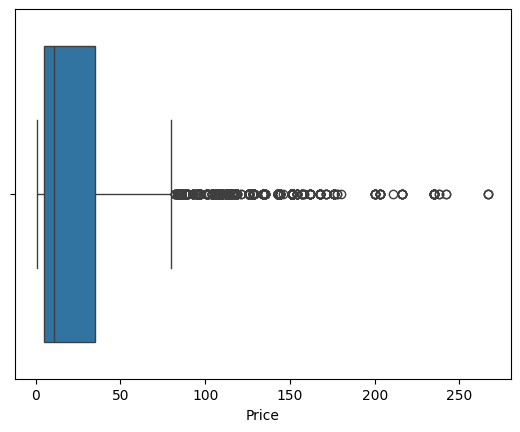

In [19]:
price_outlier= sns.boxplot(x=df["Price"])


Investigating whether the outliers are normal or not

In [20]:
price_outlier= df[(df["Price"]<lower_bound) |(df["Price"]>upper_bound)]
outlier_summary=(price_outlier.groupby(["Ticket Class", "Ticket Type"])["Price"].agg(["count", "min", "median", "max"]))
print(outlier_summary)

                          count  min  median  max
Ticket Class Ticket Type                         
First Class  Advance        112   89   118.0  135
             Anytime        184   93   114.0  267
             Off-Peak       163   82    86.0  203
Standard     Advance        179   84    84.0   86
             Anytime        500   86   151.0  171
             Off-Peak       417   84   113.0  128


In [21]:
print(price_outlier.nlargest(20,"Price")[["Price","Ticket Class","Ticket Type","Departure Station","Arrival Destination"]].to_string(index=False))

 Price Ticket Class Ticket Type     Departure Station   Arrival Destination
   267  First Class     Anytime Manchester Piccadilly         London Euston
   267  First Class     Anytime Manchester Piccadilly         London Euston
   267  First Class     Anytime Manchester Piccadilly         London Euston
   242  First Class     Anytime               Reading Liverpool Lime Street
   242  First Class     Anytime               Reading Liverpool Lime Street
   238  First Class     Anytime Liverpool Lime Street     London Paddington
   238  First Class     Anytime Liverpool Lime Street     London Paddington
   235  First Class     Anytime Liverpool Lime Street         London Euston
   235  First Class     Anytime Liverpool Lime Street         London Euston
   235  First Class     Anytime Liverpool Lime Street         London Euston
   235  First Class     Anytime Liverpool Lime Street         London Euston
   235  First Class     Anytime Liverpool Lime Street         London Euston
   235  Firs

### Price Outlier Detection

The IQR method was initially applied to the overall Price column, identifying 1,555 potential outliers using an upper bound of £80.

A second analysis was performed by grouping records according to Ticket Class and Ticket Type. This identified 3,210 potential outliers across the six groups.

The group-wise analysis revealed different upper bounds for each ticket category. Standard Off-Peak had the highest outlier percentage (18.76%).

**Treatment decision:** No records were removed or modified solely based on the IQR results. Potential outliers will be investigated further to distinguish legitimate ticket prices from possible data errors.

In [22]:
def count_iqr_outliers(group):
    Q1 = group["Price"].quantile(0.25)
    Q3 = group["Price"].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((group["Price"] < lower_bound) | (group["Price"] > upper_bound)).sum()

    return pd.Series({
        "Total Tickets": len(group),
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Upper Bound": upper_bound,
        "Lower Bound": lower_bound,
        "Outlier Count": outlier_count
    })

group_outlier = df.groupby(["Ticket Class", "Ticket Type"]).apply(count_iqr_outliers, include_groups=False).round(2)
print(group_outlier)

                          Total Tickets     Q1     Q3    IQR  Upper Bound  \
Ticket Class Ticket Type                                                    
First Class  Advance             1764.0  10.00   54.0  44.00       120.00   
             Anytime              490.0  21.25  107.0  85.75       235.62   
             Off-Peak             804.0  15.00   80.0  65.00       177.50   
Standard     Advance            15797.0   3.00   16.0  13.00        35.50   
             Anytime             4850.0   9.00   47.0  38.00       104.00   
             Off-Peak            7948.0   5.00   22.0  17.00        47.50   

                          Lower Bound  Outlier Count  
Ticket Class Ticket Type                              
First Class  Advance           -56.00           22.0  
             Anytime          -107.38            7.0  
             Off-Peak          -82.50           16.0  
Standard     Advance           -16.50         1277.0  
             Anytime           -48.00          397.0 

In [23]:
def flag_group_outliers(group):
    Q1 = group["Price"].quantile(0.25)
    Q3 = group["Price"].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    group = group.copy()

    group["Lower Bound"] = lower_bound
    group["Upper Bound"] = upper_bound

    group["Is Outlier"] = ((group["Price"] < lower_bound) | (group["Price"] > upper_bound) )

    return group


df_checked = (df.groupby(["Ticket Class", "Ticket Type"], group_keys=False)
      .apply(flag_group_outliers))

price_outliers_grouped = df_checked[df_checked["Is Outlier"]]

print("Number of potential outliers:", len(price_outliers_grouped))

print( price_outliers_grouped[ ["Ticket Class", "Ticket Type", "Price", "Lower Bound", "Upper Bound"] ].sort_values("Price", ascending=False).head(20)
)

Number of potential outliers: 3210
      Ticket Class Ticket Type  Price  Lower Bound  Upper Bound
711    First Class     Anytime    267     -107.375      235.625
11849  First Class     Anytime    267     -107.375      235.625
2042   First Class     Anytime    267     -107.375      235.625
31434  First Class     Anytime    242     -107.375      235.625
13367  First Class     Anytime    242     -107.375      235.625
20279  First Class     Anytime    238     -107.375      235.625
22488  First Class     Anytime    238     -107.375      235.625
29365  First Class    Off-Peak    203      -82.500      177.500
29631  First Class    Off-Peak    203      -82.500      177.500
23481  First Class    Off-Peak    203      -82.500      177.500
20062  First Class    Off-Peak    203      -82.500      177.500
23777  First Class    Off-Peak    203      -82.500      177.500
23692  First Class    Off-Peak    203      -82.500      177.500
23650  First Class    Off-Peak    203      -82.500      177.500
31607

/tmp/ipykernel_672/1089171506.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(flag_group_outliers))


In [24]:
group_outlier["Outlier Percentage"] = (group_outlier["Outlier Count"] / group_outlier["Total Tickets"] * 100).round(2)

print(group_outlier)

                          Total Tickets     Q1     Q3    IQR  Upper Bound  \
Ticket Class Ticket Type                                                    
First Class  Advance             1764.0  10.00   54.0  44.00       120.00   
             Anytime              490.0  21.25  107.0  85.75       235.62   
             Off-Peak             804.0  15.00   80.0  65.00       177.50   
Standard     Advance            15797.0   3.00   16.0  13.00        35.50   
             Anytime             4850.0   9.00   47.0  38.00       104.00   
             Off-Peak            7948.0   5.00   22.0  17.00        47.50   

                          Lower Bound  Outlier Count  Outlier Percentage  
Ticket Class Ticket Type                                                  
First Class  Advance           -56.00           22.0                1.25  
             Anytime          -107.38            7.0                1.43  
             Off-Peak          -82.50           16.0                1.99  
Standard

AS STANDARD Class have the highest percentage of outliers so we will check it

In [25]:
std_offpeak_outliers = price_outliers_grouped[(price_outliers_grouped["Ticket Class"] == "Standard") & (price_outliers_grouped["Ticket Type"] == "Off-Peak")]

print("Number of outliers:", len(std_offpeak_outliers))
print("\nHighest 20 prices:")
print(std_offpeak_outliers.sort_values("Price", ascending=False)[["Price", "Departure Station", "Arrival Destination", "Journey Datetime", "Railcard"]].head(20).to_string(index=False))

print("\n15 prices closest to the upper boundary:")
print(std_offpeak_outliers.nsmallest(15, "Price")[["Price", "Departure Station", "Arrival Destination", "Journey Datetime", "Railcard"]].to_string(index=False))

Number of outliers: 1491

Highest 20 prices:
 Price     Departure Station Arrival Destination    Journey Datetime         Railcard
   128 Manchester Piccadilly   London Paddington 2024-04-28 13:45:00 Haven't Railcard
   128 Manchester Piccadilly   London Paddington 2024-02-02 13:45:00 Haven't Railcard
   128 Manchester Piccadilly   London St Pancras 2024-01-27 12:00:00 Haven't Railcard
   128 Manchester Piccadilly   London Paddington 2024-04-20 07:45:00 Haven't Railcard
   128 Manchester Piccadilly   London Paddington 2024-01-06 13:45:00 Haven't Railcard
   128 Manchester Piccadilly   London Paddington 2024-02-08 01:45:00 Haven't Railcard
   128 Manchester Piccadilly   London Paddington 2024-01-26 01:45:00 Haven't Railcard
   128 Manchester Piccadilly   London Paddington 2024-01-25 13:45:00 Haven't Railcard
   128 Manchester Piccadilly   London Paddington 2024-01-25 13:45:00 Haven't Railcard
   128 Manchester Piccadilly   London St Pancras 2024-02-15 12:00:00 Haven't Railcard
   128 Ma

In [26]:
route_check = df[
    (df["Ticket Class"] == "Standard") &
    (df["Ticket Type"] == "Off-Peak") &
    (df["Departure Station"] == "Manchester Piccadilly") &
    (df["Arrival Destination"] == "London Paddington")
]

print("Number of tickets:", len(route_check))

print("\nPrice statistics:")
print(route_check["Price"].describe())

print("\nMost common prices:")
print(route_check["Price"].value_counts().head(15))

Number of tickets: 59

Price statistics:
count     59.0
mean     128.0
std        0.0
min      128.0
25%      128.0
50%      128.0
75%      128.0
max      128.0
Name: Price, dtype: float64

Most common prices:
Price
128    59
Name: count, dtype: int64


In [27]:
route_check_50 = df[
    (df["Ticket Class"] == "Standard") &
    (df["Ticket Type"] == "Off-Peak") &
    (df["Departure Station"] == "Birmingham New Street") &
    (df["Arrival Destination"] == "Reading")
]

print("Number of tickets:", len(route_check_50))

print("\nPrice statistics:")
print(route_check_50["Price"].describe())

print("\nMost common prices:")
print(route_check_50["Price"].value_counts().head(15))

Number of tickets: 29

Price statistics:
count    29.0
mean     50.0
std       0.0
min      50.0
25%      50.0
50%      50.0
75%      50.0
max      50.0
Name: Price, dtype: float64

Most common prices:
Price
50    29
Name: count, dtype: int64


### Investigation of Price Outliers

Potential outliers in the Standard – Off-Peak group were
investigated by comparing prices across individual routes.

Two routes were examined:

- Manchester Piccadilly to London Paddington:
  59 tickets were found, all priced at £128.

- Birmingham New Street to Reading:
  29 tickets were found, all priced at £50.

The repeated and consistent prices within these routes
suggest that the flagged values may reflect route-related
pricing patterns rather than obvious data-entry errors.

No prices were removed or modified based on this
investigation.

In [28]:
# Get all numerical columns
numeric_columns = df.select_dtypes(include="number").columns

print("Numerical columns:")
print(numeric_columns)

print("\nSummary statistics:")
print(df[numeric_columns].describe())

Numerical columns:
Index(['Price'], dtype='object')

Summary statistics:
              Price
count  31653.000000
mean      23.439200
std       29.997628
min        1.000000
25%        5.000000
50%       11.000000
75%       35.000000
max      267.000000


In [29]:
time_columns = [
    "Journey Datetime",
    "Arrival Time",
    "Actual Arrival Time"
]

for col in time_columns:
    print(f"\n{col}")
    print("Data type:", df[col].dtype)
    print("Missing values:", df[col].isna().sum())
    print("Sample values:")
    print(df[col].head())


Journey Datetime
Data type: datetime64[ns]
Missing values: 0
Sample values:
0   2024-01-01 11:00:00
1   2024-01-01 09:45:00
2   2024-01-02 18:15:00
3   2024-01-01 21:30:00
4   2024-01-01 16:45:00
Name: Journey Datetime, dtype: datetime64[ns]

Arrival Time
Data type: object
Missing values: 0
Sample values:
0    13:30:00
1    11:35:00
2    18:45:00
3    22:30:00
4    19:00:00
Name: Arrival Time, dtype: object

Actual Arrival Time
Data type: object
Missing values: 1880
Sample values:
0    13:30:00
1    11:40:00
2    18:45:00
3    22:30:00
4    19:00:00
Name: Actual Arrival Time, dtype: object


DELAY

In [30]:

sched  = pd.to_timedelta(df["Arrival Time"])
actual = pd.to_timedelta(df["Actual Arrival Time"])

df["delay_min"] = (actual - sched).dt.total_seconds() / 60


print(df["delay_min"].describe())
print(df.groupby("Journey Status")["delay_min"].describe())

count    29773.000000
mean         3.249689
std         14.770539
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        180.000000
Name: delay_min, dtype: float64
                  count       mean        std  min   25%   50%   75%    max
Journey Status                                                             
Cancelled           0.0        NaN        NaN  NaN   NaN   NaN   NaN    NaN
Delayed          2292.0  42.213351  34.491193  0.0  19.0  37.0  53.0  180.0
On Time         27481.0   0.000000   0.000000  0.0   0.0   0.0   0.0    0.0


In [31]:
delayed=df[df["Journey Status"]=="Delayed"]
Q1=delayed['delay_min'].quantile(0.25)
Q3=delayed['delay_min'].quantile(0.75)
IQR=Q3-Q1
upper_bound=Q3+1.5*IQR
print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Upper bound:",upper_bound)
delay_outliers=delayed[delayed['delay_min']>upper_bound]
print("Number of potential outliers:",len(delay_outliers))
print("Biggest delay:",delayed['delay_min'].max())

Q1: 19.0
Q3: 53.0
IQR: 34.0
Upper bound: 104.0
Number of potential outliers: 130
Biggest delay: 180.0


In [32]:
delay_outliers=delay_outliers.copy()
delay_outliers["route"]=delay_outliers["Departure Station"]+"->"+delay_outliers["Arrival Destination"]
print(delay_outliers["route"].value_counts())# to know on which route the delay of the 130 outliers take place
print(delay_outliers["Reason for Delay"].value_counts()) #to count the numbers delay for each reason
print("Distinct trains:",delay_outliers.groupby(["route","Journey Datetime"]).ngroups)

route
Manchester Piccadilly->Liverpool Lime Street    74
Manchester Piccadilly->Leeds                    56
Name: count, dtype: int64
Reason for Delay
Signal Failure    77
Staff Shortage    53
Name: count, dtype: int64
Distinct trains: 80


In [33]:
delayed= delayed.copy()
delayed["route"] = delayed["Departure Station"] + " -> " + delayed["Arrival Destination"]
per_train = delayed.groupby(["route", "Journey Datetime"])["delay_min"].nunique()
print("Delayed trains:", len(per_train))
print("Trains whose tickets disagree on the delay:", (per_train > 1).sum())

Delayed trains: 1062
Trains whose tickets disagree on the delay: 0


In [34]:
df["flag_extreme_delay"] = (df["delay_min"] > upper_bound)
print(df["flag_extreme_delay"].sum())

130


130 delays exceeded the IQR upper bound (104 min). They were retained: they are concentrated on two routes and two causes, and are consistent across tickets on the same train. They cannot be confirmed as real events without the data owner, so they are flagge

In [35]:
df["flag_delayed_zero_min"] = (df["Journey Status"] == "Delayed") & (df["delay_min"] == 0)
print(df["flag_delayed_zero_min"].sum())

18


18 journeys are labelled Delayed but arrived exactly on schedule. It cannot be determined from the data which field is wrong, so they were flagged and left unchanged


LEAD HOURS : DIFFERENCE BTW PURCHASING TIOME AND JOURNEY TIME

In [36]:
df["lead_hours"]=(df["Journey Datetime"]-df["Purchase Datetime"]).dt.total_seconds()/3600
print(df["lead_hours"].describe())
print("Purchased after departure:", (df["lead_hours"]<0).sum())

count    31653.000000
mean        39.827380
std         92.121621
min          0.250556
25%          1.390556
50%         22.269722
75%         22.440556
max        687.641944
Name: lead_hours, dtype: float64
Purchased after departure: 0


There is a concentration btw 22.5 hr and21 hr which isnot normal , so we would check the hours across the ticket types  

In [37]:
Q1 = df["lead_hours"].quantile(0.25)
Q3 = df["lead_hours"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
lower = Q1 - 1.5 * IQR
print("Q1:", Q1, "Q3:", Q3, "IQR:", IQR, "LOWER:", lower, "UPPER:", upper)
print("Above upper:", (df["lead_hours"] > upper).sum())

Q1: 1.3905555555555555 Q3: 22.440555555555555 IQR: 21.05 LOWER: -30.18444444444445 UPPER: 54.01555555555556
Above upper: 3520


In [38]:
for t, g in df.groupby("Ticket Type"):
    q1, q3 = g["lead_hours"].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    above = (g["lead_hours"] > upper).sum()
    pct = above / len(g) * 100
    print(t, "| Q1:", round(q1, 2), "| Q3:", round(q3, 2), "| IQR:", round(iqr, 2),
          "| upper:", round(upper, 1), "| above:", above, "of", len(g),
          "| pct:", round(pct, 1), "%")

Advance | Q1: 22.32 | Q3: 23.42 | IQR: 1.1 | upper: 25.1 | above: 4200 of 17561 | pct: 23.9 %
Anytime | Q1: 1.29 | Q3: 1.45 | IQR: 0.16 | upper: 1.7 | above: 329 of 5340 | pct: 6.2 %
Off-Peak | Q1: 1.31 | Q3: 1.45 | IQR: 0.14 | upper: 1.7 | above: 615 of 8752 | pct: 7.0 %


In [39]:
adv = df[df["Ticket Type"] == "Advance"]
print((adv["lead_hours"] / 24).round().value_counts().sort_index().head(10))

lead_hours
0.0      456
1.0    12914
2.0      671
3.0      348
4.0      247
5.0      227
6.0      213
7.0      255
8.0      213
9.0      187
Name: count, dtype: int64


In [40]:
df["flag_advance_lt12h"] = (df["Ticket Type"] == "Advance") & (df["lead_hours"] < 12)

print(df["flag_advance_lt12h"].sum())

456


The percentage of flagged tickets was computed per ticket type as the number of tickets above the IQR upper bound divided by the total tickets of that type: 23.9% for Advance, 6.2% for Anytime and 7.0% for Off-Peak. The high Advance share reflects the tight clustering of its lead times (IQR of about 1.1 hours) rather than data errors, so no records were removed on this basis. Only 456 Advance tickets purchased less than 12 hours before departure were flagged (flag_advance_lt12h) for confirmation with the data owner, and the original values were left unchanged.

Duration



In [41]:

dep = df["Journey Datetime"] - df["Journey Datetime"].dt.normalize()

arr = pd.to_timedelta(df["Arrival Time"])

df["duration_min"] = (arr - dep).dt.total_seconds() / 60


print("Overnight journeys:", (df["duration_min"] < 0).sum())

df.loc[df["duration_min"] < 0, "duration_min"] += 1440

Overnight journeys: 961


In [42]:
print(df["duration_min"].describe())
print("Duration <= 0:", (df["duration_min"] <= 0).sum())
print("Duration > 12 hours:", (df["duration_min"] > 720).sum())

count    31653.000000
mean        71.154235
std         36.330811
min         15.000000
25%         30.000000
50%         80.000000
75%         90.000000
max        270.000000
Name: duration_min, dtype: float64
Duration <= 0: 0
Duration > 12 hours: 0


In [43]:
df["route"] = df["Departure Station"] + " -> " + df["Arrival Destination"]
route_dur = df.groupby("route")["duration_min"].nunique()
print("Routes:", len(route_dur))
print("Routes with more than one duration:", (route_dur > 1).sum())

Routes: 65
Routes with more than one duration: 0


In [44]:
route_table = df.groupby("route").agg(
    n=("route", "size"),
    duration=("duration_min", "first"),
    median_price=("Price", "median")
).sort_values("duration")

print(route_table.to_string())

                                                   n  duration  median_price
route                                                                       
Birmingham New Street -> Wolverhampton            32      15.0           1.5
Reading -> Didcot                                 48      15.0           4.0
Birmingham New Street -> Nuneaton                219      20.0           7.0
Birmingham New Street -> Coventry                 65      20.0           4.0
Manchester Piccadilly -> Warrington               15      20.0           4.0
Birmingham New Street -> Tamworth                227      20.0           8.0
Bristol Temple Meads -> Cardiff Central           16      25.0           5.0
Reading -> London Paddington                     148      25.0          13.0
Reading -> Oxford                                122      25.0           6.0
York -> Leeds                                     17      25.0           5.0
York -> Wakefield                                 15      25.0           7.0

In [45]:
r = df[df["route"] == "London Paddington -> London Waterloo"]

print("Rows:", len(r))
print("Duration:", r["duration_min"].unique())
print("Price (min / median / max):", r["Price"].min(), r["Price"].median(), r["Price"].max())
print(r["Ticket Type"].value_counts())

Rows: 68
Duration: [90.]
Price (min / median / max): 3 5.0 11
Ticket Type
Advance     29
Anytime     25
Off-Peak    14
Name: count, dtype: int64


A London Paddington to London Waterloo route has a scheduled duration of 90 minutes, which is implausible for two London stations. The 68 rows were flagged for confirmation with the data owner and left unchanged.

In [46]:
df["flag_london_to_london"] = (df["route"] == "London Paddington -> London Waterloo")
print(df["flag_london_to_london"].sum())

68


Feature Engineering

Extracting , Day,Month,Hr, weekend

In [47]:

df["day_of_week"] = df["Journey Datetime"].dt.day_name()

df["month"] = df["Journey Datetime"].dt.month

df["hour"] = df["Journey Datetime"].dt.hour

df["is_weekend"] = df["Journey Datetime"].dt.dayofweek >= 5

In [48]:
print(df.loc[0, ["Journey Datetime", "day_of_week", "month", "hour", "is_weekend"]])

Journey Datetime    2024-01-01 11:00:00
day_of_week                      Monday
month                                 1
hour                                 11
is_weekend                        False
Name: 0, dtype: object


In [49]:
print(df["is_weekend"].value_counts())
print(df["month"].value_counts().sort_index())

is_weekend
False    22666
True      8987
Name: count, dtype: int64
month
1    8111
2    7644
3    8117
4    7781
Name: count, dtype: int64


In [50]:
print("Rows:", len(df))
print("Missing Journey Datetime:", df["Journey Datetime"].isna().sum())
print("Min date:", df["Journey Datetime"].min())
print("Max date:", df["Journey Datetime"].max())

Rows: 31653
Missing Journey Datetime: 0
Min date: 2024-01-01 00:00:00
Max date: 2024-04-30 23:45:00


Revenue Per Ticket and Per Ride

In [51]:
# 1) revenue per ticket
df["revenue_per_ticket"] = df["Price"]

# 2) revenue per ride
df["revenue_per_ride"] = df.groupby(["route", "Journey Datetime"])["Price"].transform("sum")

# 3) no. of ticket sold
df["tickets_on_ride"] = df.groupby(["route", "Journey Datetime"])["Price"].transform("size")

print(df[["revenue_per_ticket", "revenue_per_ride", "tickets_on_ride"]].describe().round(1))
print(df.loc[0, ["route", "Journey Datetime", "Price", "revenue_per_ride", "tickets_on_ride"]])

       revenue_per_ticket  revenue_per_ride  tickets_on_ride
count             31653.0           31653.0          31653.0
mean                 23.4              69.2              2.6
std                  30.0             153.0              2.2
min                   1.0               1.0              1.0
25%                   5.0               8.0              1.0
50%                  11.0              22.0              2.0
75%                  35.0              70.0              3.0
max                 267.0            1973.0             15.0
route               London Paddington -> Liverpool Lime Street
Journey Datetime                           2024-01-01 11:00:00
Price                                                       43
revenue_per_ride                                            43
tickets_on_ride                                              1
Name: 0, dtype: object


In [52]:
print(df.groupby(["route", "Journey Datetime"]).ngroups)

19871


In [53]:
df["Price"].sum()

np.int64(741921)

Seven features were engineered: day of week, month, hour, weekend flag, scheduled journey duration (minutes), delay (minutes), and revenue per ticket and per ride (gross, before refunds). All were complete except delay, which is missing for the 1,880 cancelled journeys because they have no actual arrival time; these were left blank by design.



In [54]:
new_cols = ["day_of_week", "month", "hour", "is_weekend", "duration_min",
            "delay_min", "revenue_per_ticket", "revenue_per_ride", "tickets_on_ride"]

print(df[new_cols].isna().sum())
print(df[new_cols].dtypes)

day_of_week              0
month                    0
hour                     0
is_weekend               0
duration_min             0
delay_min             1880
revenue_per_ticket       0
revenue_per_ride         0
tickets_on_ride          0
dtype: int64
day_of_week            object
month                   int32
hour                    int32
is_weekend               bool
duration_min          float64
delay_min             float64
revenue_per_ticket      int64
revenue_per_ride        int64
tickets_on_ride         int64
dtype: object


In [55]:
print(df["hour"].value_counts().sort_index().head(6))

hour
0     853
1     644
2     942
3     543
4    1041
5     725
Name: count, dtype: int64


In [56]:
night = df[df["hour"] < 5]

print("Night departures:", len(night))
print("Share:", round(len(night) / len(df) * 100, 1), "%")

Night departures: 4023
Share: 12.7 %


In [57]:
print(night["route"].value_counts().head(5))
print(night["Journey Datetime"].dt.strftime("%H:%M").value_counts().head(5))

route
Liverpool Lime Street -> Manchester Piccadilly    1020
London Kings Cross -> York                         545
London Euston -> Birmingham New Street             481
London St Pancras -> Birmingham New Street         454
Manchester Piccadilly -> Liverpool Lime Street     446
Name: count, dtype: int64
Journey Datetime
04:30    452
00:00    448
02:00    425
04:15    383
01:45    319
Name: count, dtype: int64


4,023 journeys (12.7%) depart between 00:00 and 04:59, concentrated on high-volume routes at fixed times such as 04:30, 00:00 and 02:00. This is atypical for UK passenger services. No other field is inconsistent for these rows, so they were flagged (flag_night_departure) for confirmation with the data owner and retained.

In [58]:
df["flag_night_departure"] = df["hour"] < 5

print(df["flag_night_departure"].sum())

4023


In [59]:
flag_cols = [c for c in df.columns if c.startswith("flag_")]

print(df[flag_cols].sum())
print("Rows with at least one flag:", df[flag_cols].any(axis=1).sum())

flag_extreme_delay        130
flag_delayed_zero_min      18
flag_advance_lt12h        456
flag_london_to_london      68
flag_night_departure     4023
dtype: int64
Rows with at least one flag: 4236


Five review flags were added without removing or changing any record. In total, 4,236 rows (13.4%) carry at least one flag, mostly night departures. Flagged rows are retained pending confirmation with the data owner.

CORRECTING INCONSISTENCY


In [60]:
df["Arrival Destination (raw)"] = df["Arrival Destination"]
correct_inconsistency("Arrival Destination", "Edinburgh", "Edinburgh Waverley")
print(df["Arrival Destination"].value_counts().get("Edinburgh", 0))
print(df["Arrival Destination"].value_counts()["Edinburgh Waverley"])

0
332


In [61]:
print(df["route"].nunique())

65


CHECKIMG SKEWNESS

In [62]:
cols = ["Price", "delay_min", "duration_min", "lead_hours",
        "revenue_per_ride", "tickets_on_ride", "hour", "month"]

print(df[cols].skew().round(2))

Price               2.47
delay_min           6.62
duration_min        1.11
lead_hours          3.69
revenue_per_ride    5.73
tickets_on_ride     2.02
hour               -0.05
month              -0.00
dtype: float64


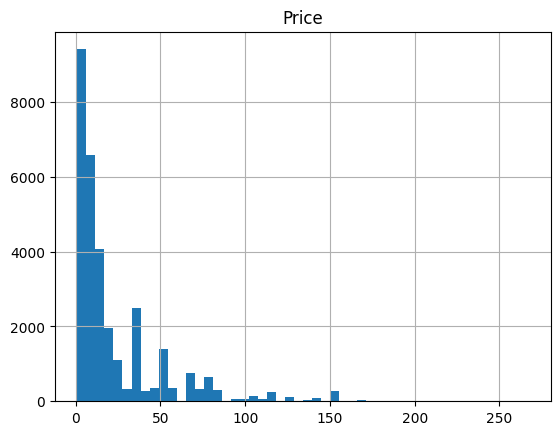

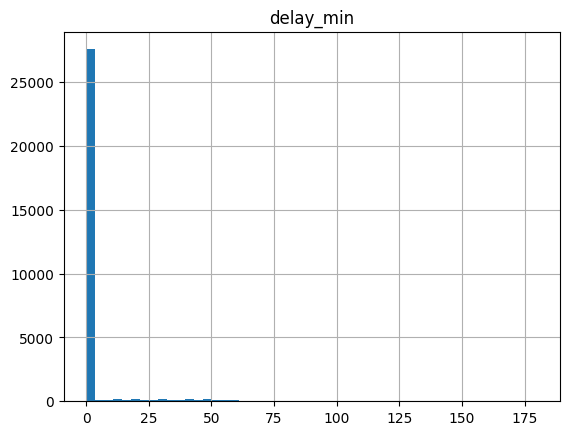

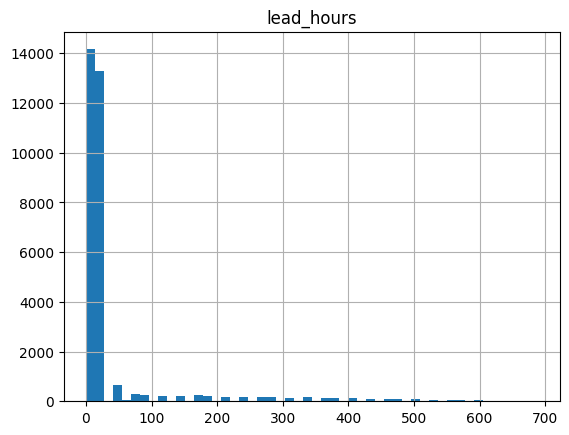

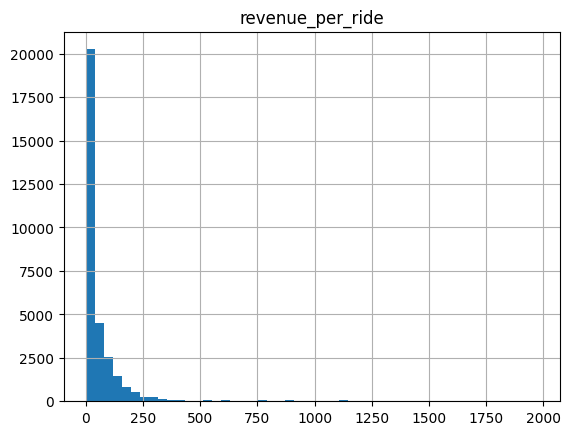

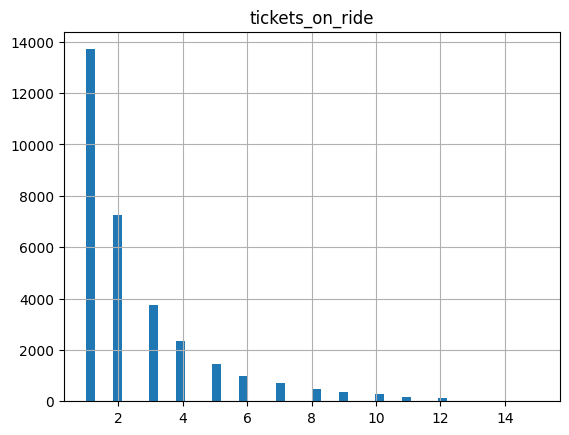

In [63]:
skewed = ["Price", "delay_min", "lead_hours", "revenue_per_ride", "tickets_on_ride"]

for c in skewed:
    df[c].hist(bins=50)
    plt.title(c)
    plt.show()

In [64]:
for c in ["Price", "lead_hours", "revenue_per_ride", "tickets_on_ride"]:
    df[c + "_log"] = np.log1p(df[c])

log_cols = ["Price_log", "lead_hours_log", "revenue_per_ride_log", "tickets_on_ride_log"]
print(df[log_cols].skew().round(2))

Price_log               0.43
lead_hours_log          0.52
revenue_per_ride_log    0.46
tickets_on_ride_log     0.94
dtype: float64


In [65]:
delayed = df[df["Journey Status"] == "Delayed"]["delay_min"]

print("raw  :", round(delayed.skew(), 2))
print("log1p:", round(np.log1p(delayed).skew(), 2))
print("sqrt :", round(np.sqrt(delayed).skew(), 2))

df["delay_sqrt"] = np.sqrt(df["delay_min"])

raw  : 1.94
log1p: -0.99
sqrt : 0.55


Skewness was checked on all numeric columns. Price (2.47), lead time (3.69), revenue per ride (5.73) and tickets per ride (2.02) were strongly right-skewed and were reduced with a log1p transform (to 0.43, 0.52, 0.46 and 0.94). Delay (6.62) is dominated by zeros for on-time journeys, so the transform was assessed on delayed journeys only, where a square root worked better (skew from 1.94 to 0.55) than a log (-0.99). Transformed values were stored in new columns and the originals were left unchanged. Hour and month are symmetric and were not transformed.

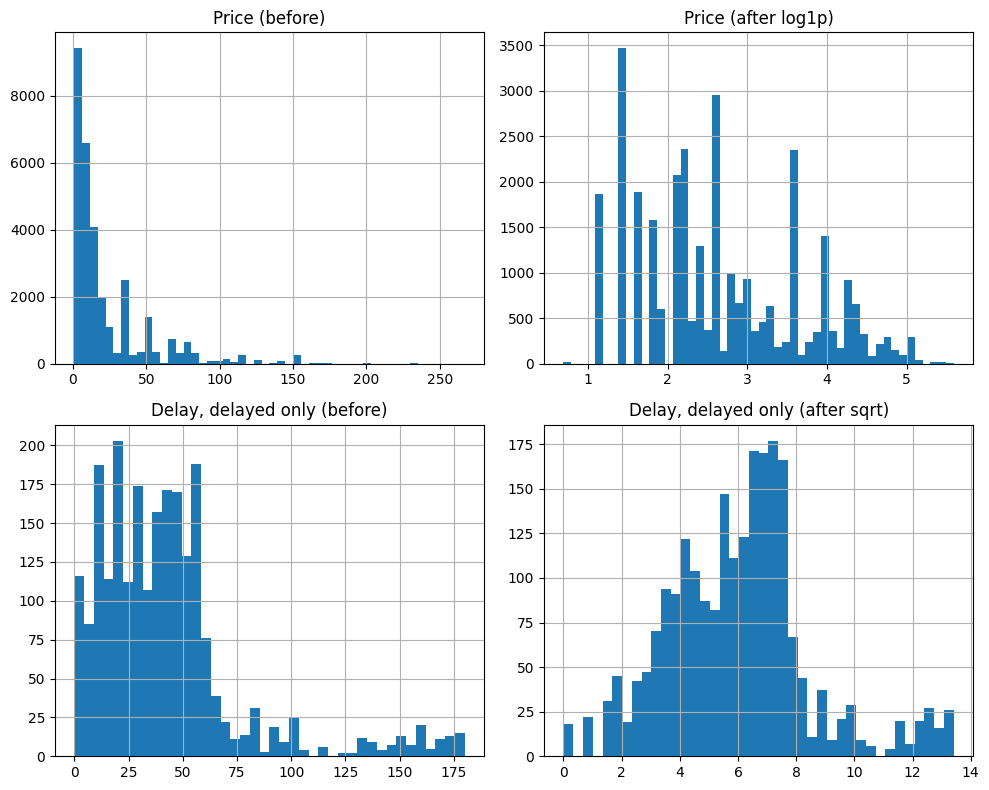

In [66]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

df["Price"].hist(bins=50, ax=ax[0, 0]);      ax[0, 0].set_title("Price (before)")
df["Price_log"].hist(bins=50, ax=ax[0, 1]);  ax[0, 1].set_title("Price (after log1p)")

delayed_raw = df[df["Journey Status"] == "Delayed"]["delay_min"]
delayed_raw.hist(bins=40, ax=ax[1, 0]);           ax[1, 0].set_title("Delay, delayed only (before)")
np.sqrt(delayed_raw).hist(bins=40, ax=ax[1, 1]);  ax[1, 1].set_title("Delay, delayed only (after sqrt)")

plt.tight_layout()
plt.show()

In [67]:
cat_cols = ["Purchase Type", "Payment Method", "Railcard", "Ticket Class", "Ticket Type",
            "Journey Status", "Reason for Delay",
            "Departure Station", "Arrival Destination", "day_of_week"]

df_enc = df[cat_cols + ["Refund Request", "Price"]].copy()
df_enc["Refund Request"] = df_enc["Refund Request"].map({"No": 0, "Yes": 1})

df_enc = encode_categorical(df_enc, method="frequency", target_variable="Refund Request")

print(df_enc.shape)
print(df_enc.columns.tolist())

(31653, 35)
['Departure Station', 'Arrival Destination', 'Refund Request', 'Price', 'Purchase Type_Online', 'Purchase Type_Station', 'Payment Method_Contactless', 'Payment Method_Credit Card', 'Payment Method_Debit Card', 'Railcard_Adult', 'Railcard_Disabled', "Railcard_Haven't Railcard", 'Railcard_Senior', 'Ticket Class_First Class', 'Ticket Class_Standard', 'Ticket Type_Advance', 'Ticket Type_Anytime', 'Ticket Type_Off-Peak', 'Journey Status_Cancelled', 'Journey Status_Delayed', 'Journey Status_On Time', 'Reason for Delay_No delay', 'Reason for Delay_Signal Failure', 'Reason for Delay_Signal failure', 'Reason for Delay_Staff Shortage', 'Reason for Delay_Technical Issue', 'Reason for Delay_Traffic', 'Reason for Delay_Weather Conditions', 'day_of_week_Friday', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday']


In [70]:
df_enc.to_excel("railway_encoded.xlsx", index=False)
files.download("railway_encoded.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [71]:
from sklearn.preprocessing import StandardScaler

num_cols = ["Price_log", "lead_hours_log", "revenue_per_ride_log", "tickets_on_ride_log",
            "delay_sqrt", "duration_min", "hour", "month"]

df_scaled = df[num_cols].copy()
df_scaled[num_cols] = StandardScaler().fit_transform(df_scaled[num_cols])

print(df_scaled.describe().loc[["mean", "std", "min", "max"]].round(2))

      Price_log  lead_hours_log  revenue_per_ride_log  tickets_on_ride_log  \
mean       0.00            0.00                 -0.00                -0.00   
std        1.00            1.00                  1.00                 1.00   
min       -1.88           -1.39                 -2.01                -0.90   
max        2.86            2.67                  3.31                 3.35   

      delay_sqrt  duration_min  hour  month  
mean        0.00         -0.00 -0.00  -0.00  
std         1.00          1.00  1.00   1.00  
min        -0.27         -1.55 -1.89  -1.33  
max         7.43          5.47  1.85   1.35  


In [72]:
df_model = pd.concat([
    df_enc.drop(columns=["Price", "Refund Request"]),
    df_scaled,
    df[["is_weekend"]],
    df_enc[["Refund Request"]]
], axis=1)

print(df_model.shape)
print(df_model.isna().sum()[df_model.isna().sum() > 0])

(31653, 43)
delay_sqrt    1880
dtype: int64


In [73]:
# 1) اfeatures والـ flags
df.to_excel("railway_final.xlsx", index=False)

# 2) الجدول الجاهز للموديل
df_model.to_excel("railway_model_ready.xlsx", index=False)

files.download("railway_final.xlsx")
files.download("railway_model_ready.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [68]:
df.to_excel("railway_final.xlsx", index=False) # before last final clean
files.download("railway_final.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>